# Redes Neuronales V — Parte 3
### Red neuronal siamesa con Triplet Loss en TensorFlow + Keras y comparación con PyTorch

---

**Universidad de Cundinamarca**

**CADI:** Deep Learning — Conceptos

**Estudiante:** Ruby Dayana Cárdenas Gómez

**Docente:** Nidia Stella García Roa

**Repositorio GitHub:** `https://github.com/RubyDayana/redes-neuronales-v.git`

---

### ¿Qué se hace en este notebook?

En la Parte 2 se construyó y evaluó la red siamesa con PyTorch. Aquí se implementa **la misma idea con TensorFlow + Keras**
y se comparan los resultados. Se usa la misma arquitectura (≈250 000 parámetros), la misma Triplet Loss *batch-all*,
los mismos repartos de datos y el mismo protocolo de evaluación, para que la comparación entre frameworks sea justa.

Lo que se hace, en orden:

1. Cargar los rostros de la Parte 1 y repetir la división en entrenamiento y prueba.
2. Construir la **red base** y el **modelo siamés de tres ramas** (ancla, positiva, negativa) con pesos compartidos, que es la forma clásica de dibujar una red siamesa en Keras.
3. Implementar la **Triplet Loss** y el **bucle de entrenamiento** con `tf.GradientTape`.
4. Entrenar y hacer las pruebas de verificación, identificación y one-shot / few-shot en 10 repartos.
5. **Comparar con PyTorch**: resultados, tiempos y diferencias de implementación.

### Glosario rápido

| Término | Qué significa aquí |
|---|---|
| **Red base** | La red que convierte una imagen en un embedding de 64 números. Es la parte que se entrena y se reutiliza. |
| **Modelo siamés de tres ramas** | Un modelo con tres entradas (ancla, positiva, negativa) que pasan por **la misma red base** (mismos pesos) y salen tres embeddings que se comparan en la pérdida. |
| **`tf.GradientTape`** | Mecanismo de TensorFlow para calcular gradientes en un bucle de entrenamiento escrito a mano. |
| **Batch-all** | Variante de Triplet Loss que usa todas las tripletas válidas de un lote y promedia las que siguen activas (se explicó en la Parte 2). |

In [1]:
import os, glob, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, balanced_accuracy_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
tf.config.experimental.enable_op_determinism()      # mismas operaciones => mismos resultados en cada ejecución (reproducibilidad)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", len(tf.config.list_physical_devices("GPU")))

TAM = 64

def cargar_rostros(carpeta="datos/rostros", tam=TAM):
    X, y = [], []
    personas = sorted(d for d in os.listdir(carpeta) if os.path.isdir(f"{carpeta}/{d}"))
    for k, p in enumerate(personas):
        for f in sorted(glob.glob(f"{carpeta}/{p}/*.png")):
            X.append(np.asarray(Image.open(f).convert("RGB").resize((tam, tam), Image.LANCZOS)))
            y.append(k)
    return np.stack(X), np.array(y), personas

def dividir(y, semilla, frac_test=0.35):
    """El mismo reparto estratificado que en la Parte 2 (misma semilla => mismas fotos de prueba)."""
    rng = np.random.RandomState(semilla)
    tr, te = [], []
    for k in np.unique(y):
        idx = rng.permutation(np.where(y == k)[0])
        n_te = max(1, int(round(frac_test * len(idx))))
        te += idx[:n_te].tolist(); tr += idx[n_te:].tolist()
    return np.array(sorted(tr)), np.array(sorted(te))

X, y, PERSONAS = cargar_rostros()
tr, te = dividir(y, 0)
print("Imágenes:", X.shape, "| personas:", PERSONAS, "| entrenamiento:", len(tr), "| prueba:", len(te))

I0000 00:00:1793751318.356500    1108 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793751319.569050    1108 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | GPU: 0
Imágenes: (38, 64, 64, 3) | personas: ['ayis', 'gaby', 'yeyo'] | entrenamiento: 25 | prueba: 13


## 1. La red base y el modelo siamés de tres ramas

La **red base** es la misma de la Parte 2: cuatro bloques *Conv → BatchNorm → ReLU → MaxPool*, promedio global,
*Dropout* y una capa densa de 64 neuronas con **normalización L2**. El modelo siamés de tres ramas se arma aplicando
esa red base tres veces: Keras reutiliza la misma instancia, por lo que los **pesos se comparten** y no hay tres redes
distintas.

In [2]:
def crear_red_base(dim=64):
    entrada = keras.Input((TAM, TAM, 3), name="rostro")
    x = entrada
    for filtros in (32, 64, 128, 128):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(dim)(x)
    salida = layers.UnitNormalization(name="embedding_L2")(x)          # norma 1
    return keras.Model(entrada, salida, name="red_base")

def crear_modelo_siames(red_base):
    """Tres entradas -> la MISMA red base -> tres embeddings (pesos compartidos)."""
    a, p, n = (keras.Input((TAM, TAM, 3), name=nombre) for nombre in ("ancla", "positiva", "negativa"))
    salida = layers.Concatenate(name="embeddings")([red_base(a), red_base(p), red_base(n)])
    return keras.Model([a, p, n], salida, name="siames_tres_ramas")

red_base = crear_red_base()
siames = crear_modelo_siames(red_base)
print(f"Parámetros de la red base: {red_base.count_params():,}  |  parámetros del modelo de tres ramas: {siames.count_params():,}  (los mismos: los pesos se comparten)")
red_base.summary()

Parámetros de la red base: 250,144  |  parámetros del modelo de tres ramas: 250,144  (los mismos: los pesos se comparten)


Model: "red_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rostro (InputLayer)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_L2                    │ (None, 64)             │             0 │
│ (UnitNormalization)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250,144 (977.12 KB)

 Trainable params: 249,440 (974.38 KB)

 Non-trainable params: 704 (2.75 KB)

In [3]:
# Comprobación de que las tres ramas comparten pesos: la misma imagen en cualquier rama da el mismo embedding
img = ((X[:1].astype("float32") / 255) - 0.5) / 0.25
e = siames([img, img, img], training=False).numpy()
print("Forma de la salida (1 imagen, 3 ramas x 64):", e.shape)
print("Diferencia máxima entre los embeddings de las 3 ramas:", float(np.abs(e[:, :64] - e[:, 64:128]).max() + np.abs(e[:, :64] - e[:, 128:]).max()))
print("Norma de cada embedding:", np.linalg.norm(e.reshape(3, 64), axis=1).round(3))

Forma de la salida (1 imagen, 3 ramas x 64): (1, 192)
Diferencia máxima entre los embeddings de las 3 ramas: 0.0
Norma de cada embedding: [1. 1. 1.]


## 2. Triplet Loss y entrenamiento

Se implementa la misma **Triplet Loss *batch-all*** que en PyTorch, con operaciones de TensorFlow. Primero se comprueba la
fórmula con las tres tripletas de ejemplo de la Parte 2 (fácil, semi-dura y dura), cuyo resultado a mano se conoce.

El **aumento de datos** usa capas de Keras (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomBrightness`,
`RandomContrast`) que solo actúan durante el entrenamiento.

Tripleta fácil    : d(a,p)=0.040  d(a,n)=4.000  pérdida = 0.000
Tripleta semi-dura: d(a,p)=0.040  d(a,n)=0.200  pérdida = 0.140
Tripleta dura     : d(a,p)=0.400  d(a,n)=0.100  pérdida = 0.600
Valores esperados de la Parte 2: 0.000, 0.140 y 0.600


  paso   75  pérdida 0.3148  tripletas activas  28.7 %


  paso  150  pérdida 0.2637  tripletas activas   4.7 %


  paso  225  pérdida 0.1400  tripletas activas   1.0 %


  paso  300  pérdida 0.0313  tripletas activas   0.2 %
Tiempo de entrenamiento: 18.1 s


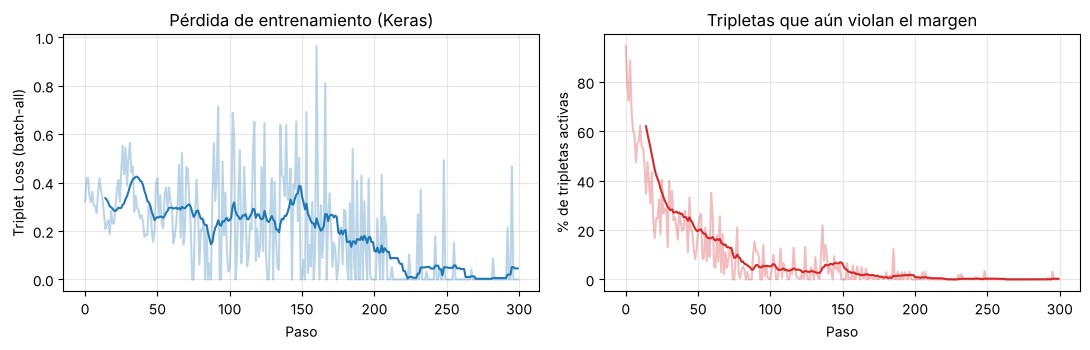

Dispersión de los embeddings: 0.106  (esperado si no hay colapso: ~0.125)


In [4]:
def triplet_loss_tripletas(ancla, pos, neg, margen=0.3):
    """Triplet Loss para tripletas dadas, con la distancia al cuadrado."""
    d_ap = tf.reduce_sum(tf.square(ancla - pos), axis=1)
    d_an = tf.reduce_sum(tf.square(ancla - neg), axis=1)
    return tf.reduce_mean(tf.nn.relu(d_ap - d_an + margen)), d_ap, d_an

# El mismo ejemplo a mano de la Parte 2
ancla = tf.constant([[1.0, 0.0]] * 3)
pos = tf.constant([[0.98, 0.199], [0.98, 0.199], [0.8, 0.6]])
neg = tf.constant([[-1.0, 0.0], [0.9, 0.436], [0.95, 0.312]])
for nombre, i in zip(["fácil", "semi-dura", "dura"], range(3)):
    perdida, d_ap, d_an = triplet_loss_tripletas(ancla[i:i + 1], pos[i:i + 1], neg[i:i + 1])
    print(f"Tripleta {nombre:9s}: d(a,p)={float(d_ap[0]):.3f}  d(a,n)={float(d_an[0]):.3f}  pérdida = {float(perdida):.3f}")
print("Valores esperados de la Parte 2: 0.000, 0.140 y 0.600")

def perdida_batch_all(emb, etiquetas, margen=0.3):
    """Todas las tripletas válidas del lote; la pérdida es el promedio de las que siguen activas."""
    sq = tf.reduce_sum(tf.square(emb), axis=1)
    d = tf.maximum(sq[:, None] - 2 * emb @ tf.transpose(emb) + sq[None, :], 0.0)       # distancias al cuadrado
    misma = etiquetas[:, None] == etiquetas[None, :]
    yo = tf.eye(tf.shape(etiquetas)[0], dtype=tf.bool)
    valida = tf.cast((misma & ~yo)[:, :, None] & (~misma)[:, None, :], tf.float32)
    perdida = tf.nn.relu(d[:, :, None] - d[:, None, :] + margen) * valida
    activas = tf.reduce_sum(tf.cast(perdida > 0, tf.float32))
    return tf.reduce_sum(perdida) / tf.maximum(activas, 1.0), activas / tf.reduce_sum(valida)

def crear_aumento():
    """Capas de aumento de datos de Keras (solo actúan en entrenamiento). Se crean con la semilla ya fijada."""
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(10 / 360),
        layers.RandomZoom((-0.2, 0.0)),
        layers.RandomBrightness(0.3, value_range=(0, 255)),
        layers.RandomContrast(0.3),
    ], name="aumento")

def muestrear_lote(y_tr, rng, K=6):
    idx = []
    for k in np.unique(y_tr):
        pool = np.where(y_tr == k)[0]
        idx += rng.choice(pool, size=K, replace=len(pool) < K).tolist()
    return np.array(idx)

def normalizar(imgs):
    return (tf.cast(imgs, tf.float32) / 255 - 0.5) / 0.25

def paso_entrenamiento(red, aumento, optimizador, lote_uint8, etiquetas, margen):
    # el aumento trabaja en escala 0-255; después se normaliza
    lote = normalizar(tf.clip_by_value(aumento(tf.cast(lote_uint8, tf.float32), training=True), 0, 255))
    with tf.GradientTape() as cinta:
        perdida, activas = perdida_batch_all(red(lote, training=True), etiquetas, margen)
    grads = cinta.gradient(perdida, red.trainable_variables)
    optimizador.apply_gradients(zip(grads, red.trainable_variables))
    return perdida, activas

def entrenar(X_tr, y_tr, semilla=0, pasos=300, margen=0.3, dim=64, lr=2e-3, verbose=False):
    keras.utils.set_random_seed(semilla); rng = np.random.RandomState(semilla)
    red = crear_red_base(dim)
    cosine = keras.optimizers.schedules.CosineDecay(lr, pasos)
    opt = keras.optimizers.AdamW(learning_rate=cosine, weight_decay=1e-4)
    opt.build(red.trainable_variables)                     # crea las variables del optimizador ANTES de compilar el paso
    aumento = crear_aumento()
    paso_compilado = tf.function(lambda lote, et: paso_entrenamiento(red, aumento, opt, lote, et, margen))
    hist = {"perdida": [], "activas": []}
    for paso in range(pasos):
        idx = muestrear_lote(y_tr, rng)
        p, a = paso_compilado(tf.constant(X_tr[idx]), tf.constant(y_tr[idx]))
        hist["perdida"].append(float(p)); hist["activas"].append(float(a))
        if verbose and (paso + 1) % 75 == 0:
            print(f"  paso {paso + 1:4d}  pérdida {np.mean(hist['perdida'][-75:]):.4f}  tripletas activas {np.mean(hist['activas'][-75:]) * 100:5.1f} %")
    return red, hist

def incrustar(red, imgs_uint8):
    return red(normalizar(imgs_uint8), training=False).numpy()

t0 = time.time()
red, hist = entrenar(X[tr], y[tr], semilla=0, verbose=True)
tiempo_keras = time.time() - t0
print(f"Tiempo de entrenamiento: {tiempo_keras:.1f} s")
os.makedirs("modelos", exist_ok=True)
red.save("modelos/siamesa_keras.keras")

suave = lambda v, w=15: np.convolve(v, np.ones(w) / w, mode="valid")
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].plot(hist["perdida"], alpha=0.3, color="tab:blue"); ejes[0].plot(range(14, 300), suave(hist["perdida"]), color="tab:blue")
ejes[0].set(xlabel="Paso", ylabel="Triplet Loss (batch-all)", title="Pérdida de entrenamiento (Keras)")
ejes[1].plot(np.array(hist["activas"]) * 100, alpha=0.3, color="tab:red"); ejes[1].plot(range(14, 300), suave(np.array(hist["activas"]) * 100), color="tab:red")
ejes[1].set(xlabel="Paso", ylabel="% de tripletas activas", title="Tripletas que aún violan el margen")
plt.tight_layout(); plt.show()
e_all = incrustar(red, X)
print(f"Dispersión de los embeddings: {e_all.std(axis=0).mean():.3f}  (esperado si no hay colapso: ~0.125)")

**Lectura.** Las tres ramas comparten pesos: la misma imagen produce exactamente el mismo embedding en cualquiera de ellas (diferencia 0.0) y el modelo de tres ramas
tiene los mismos parámetros que la red base (250 144, que incluye 704 valores no entrenables de la normalización por lotes; por eso es una cifra un poco mayor que las
249 440 entrenables de PyTorch). La Triplet Loss de TensorFlow reproduce a mano las tres tripletas de ejemplo (0.000, 0.140 y 0.600), igual que la implementación de PyTorch.

El entrenamiento con **batch-all** aprende: la pérdida baja de 0.31 a 0.03 y las tripletas activas pasan de 28.7 % a 0.2 % en 300 pasos (18 s), con una dispersión de
embeddings de 0.106 (sin colapso). Se observa que la pérdida llega a un valor menor que en PyTorch (0.216), lo que indica que esta versión se ajusta más a las fotos de
entrenamiento; si eso ayuda o perjudica con fotos nuevas es lo que se mide a continuación.

## 3. Pruebas de reconocimiento

Para que los resultados se repitan idénticos en cada ejecución se activa `tf.config.experimental.enable_op_determinism()` y se fija la semilla en cada entrenamiento. Se usan exactamente las mismas funciones de evaluación de la Parte 2 (verificación con AUC, EER y umbral elegido con pares
de entrenamiento; identificación con prototipos; one-shot y few-shot).

Reparto 0, red siamesa en Keras (fotos de prueba)
  Verificación: AUC 0.777 | EER 0.260 | exactitud balanceada 0.740 (umbral 0.98)
  Identificación: exactitud balanceada 0.700


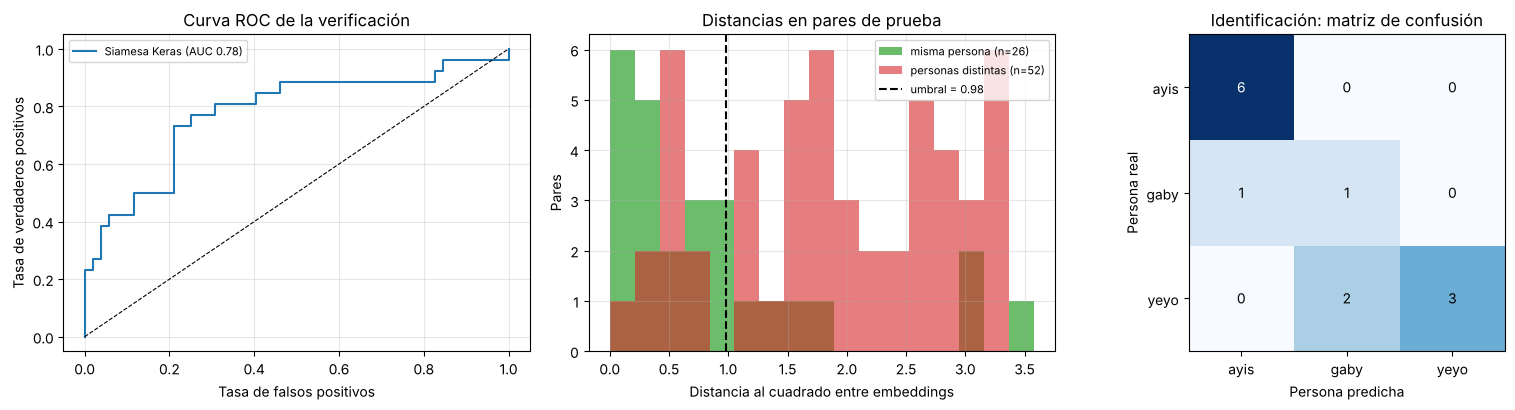

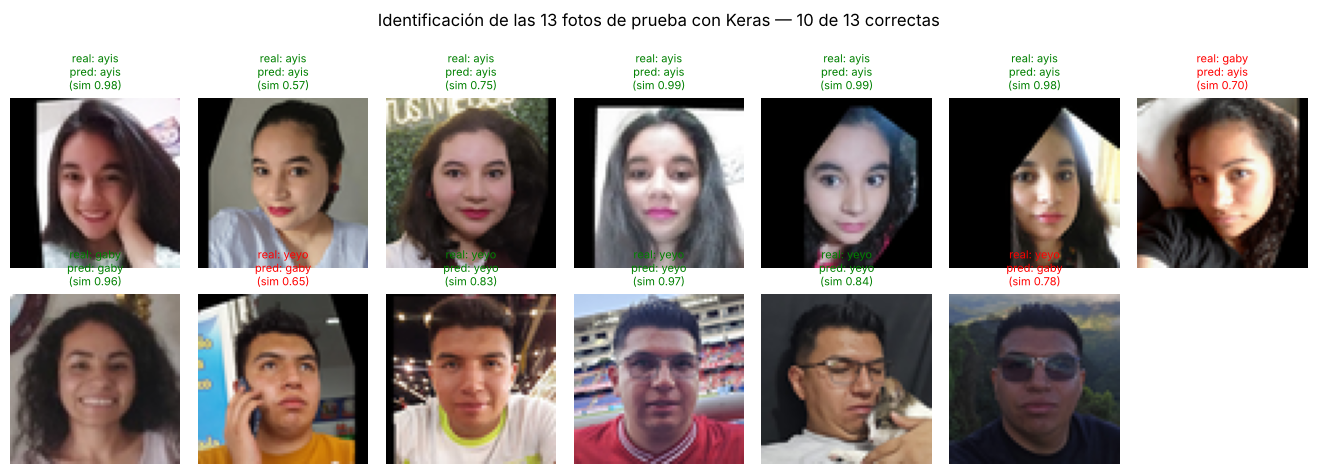

In [5]:
def pares(etiquetas):
    i, j = np.triu_indices(len(etiquetas), 1)
    return i, j, etiquetas[i] == etiquetas[j]

def distancias(emb, i, j):
    return ((emb[i] - emb[j]) ** 2).sum(1)

def tasa_igual_error(misma, puntaje):
    fpr, tpr, _ = roc_curve(misma, puntaje)
    fnr = 1 - tpr
    k = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[k] + fnr[k]) / 2)

def verificacion(emb, y_, tr_idx, te_idx):
    i, j, misma = pares(y_[te_idx]); d = distancias(emb[te_idx], i, j)
    itr, jtr, mtr = pares(y_[tr_idx]); dtr = distancias(emb[tr_idx], itr, jtr)
    cand = np.linspace(0, 4, 401)
    bal_tr = [(np.mean(dtr[mtr] < u) + np.mean(dtr[~mtr] >= u)) / 2 for u in cand]
    u = float(cand[int(np.argmax(bal_tr))])
    pred = d < u
    return {"auc": roc_auc_score(misma, -d), "eer": tasa_igual_error(misma, -d), "umbral": u,
            "acc_bal": (np.mean(pred[misma]) + np.mean(~pred[~misma])) / 2}

def prototipos(emb_ref, y_ref):
    clases = np.unique(y_ref)
    P = np.stack([emb_ref[y_ref == k].mean(0) for k in clases])
    return clases, P / np.linalg.norm(P, axis=1, keepdims=True)

def identificar(emb_ref, y_ref, emb_q):
    clases, P = prototipos(emb_ref, y_ref)
    return clases[(emb_q @ P.T).argmax(1)]

def identificacion(emb, y_, tr_idx, te_idx):
    pred = identificar(emb[tr_idx], y_[tr_idx], emb[te_idx])
    return {"acc_bal": balanced_accuracy_score(y_[te_idx], pred), "pred": pred}

def n_shot(emb, y_, tr_idx, te_idx, k, rng, sorteos=30):
    accs = []
    for _ in range(sorteos):
        ref = []
        for c in np.unique(y_):
            pool = tr_idx[y_[tr_idx] == c]
            ref += rng.choice(pool, size=min(k, len(pool)), replace=False).tolist()
        ref = np.array(ref)
        accs.append(balanced_accuracy_score(y_[te_idx], identificar(emb[ref], y_[ref], emb[te_idx])))
    return float(np.mean(accs))

v, ident = verificacion(e_all, y, tr, te), identificacion(e_all, y, tr, te)
print("Reparto 0, red siamesa en Keras (fotos de prueba)")
print(f"  Verificación: AUC {v['auc']:.3f} | EER {v['eer']:.3f} | exactitud balanceada {v['acc_bal']:.3f} (umbral {v['umbral']:.2f})")
print(f"  Identificación: exactitud balanceada {ident['acc_bal']:.3f}")

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
i, j, misma = pares(y[te]); d = distancias(e_all[te], i, j)
fpr, tpr, _ = roc_curve(misma, -d)
ejes[0].plot(fpr, tpr, label=f"Siamesa Keras (AUC {roc_auc_score(misma, -d):.2f})"); ejes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ejes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curva ROC de la verificación"); ejes[0].legend(fontsize=8)
bins = np.linspace(0, max(d.max(), 1.0), 18)
ejes[1].hist(d[misma], bins, alpha=0.7, color="tab:green", label=f"misma persona (n={misma.sum()})")
ejes[1].hist(d[~misma], bins, alpha=0.6, color="tab:red", label=f"personas distintas (n={(~misma).sum()})")
ejes[1].axvline(v["umbral"], color="k", ls="--", label=f"umbral = {v['umbral']:.2f}")
ejes[1].set(xlabel="Distancia al cuadrado entre embeddings", ylabel="Pares", title="Distancias en pares de prueba"); ejes[1].legend(fontsize=8)
cm = confusion_matrix(y[te], ident["pred"], labels=range(len(PERSONAS)))
ejes[2].imshow(cm, cmap="Blues"); ejes[2].grid(False)
for a in range(cm.shape[0]):
    for b in range(cm.shape[1]):
        ejes[2].text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
ejes[2].set(xticks=range(len(PERSONAS)), yticks=range(len(PERSONAS)), xticklabels=PERSONAS, yticklabels=PERSONAS,
            xlabel="Persona predicha", ylabel="Persona real", title="Identificación: matriz de confusión")
plt.tight_layout(); plt.show()

# Evidencia de ejecución: fotos de prueba, persona real y predicción
pred = ident["pred"]; n = len(te)
sim_all = e_all[te] @ prototipos(e_all[tr], y[tr])[1].T
fig, ejes = plt.subplots(2, int(np.ceil(n / 2)), figsize=(1.9 * int(np.ceil(n / 2)), 4.6))
for k, (eje, idx) in enumerate(zip(ejes.ravel(), te)):
    eje.imshow(X[idx]); eje.axis("off")
    eje.set_title(f"real: {PERSONAS[y[idx]]}\npred: {PERSONAS[pred[k]]}\n(sim {sim_all[k].max():.2f})", fontsize=8, color="green" if pred[k] == y[idx] else "red")
for eje in ejes.ravel()[n:]: eje.axis("off")
plt.suptitle(f"Identificación de las {n} fotos de prueba con Keras — {int((pred == y[te]).sum())} de {n} correctas", y=1.02)
plt.tight_layout(); plt.show()

**Lectura (reparto 0).** Con las 13 fotos de prueba, la versión de Keras obtiene un AUC de verificación de **0.777** (EER 0.260, exactitud balanceada 0.740 con un umbral de 0.98) y una
exactitud balanceada de identificación de **0.700**. Frente al reparto 0 de PyTorch (AUC 0.823 e identificación 0.889), Keras queda algo por debajo en este reparto, pero un solo reparto con 13 fotos no permite
comparar frameworks: la sección siguiente usa 10 repartos.

## 4. 10 repartos, one-shot y few-shot

Se repite el entrenamiento y la evaluación con los **mismos 10 repartos** de la Parte 2 (semillas 0 a 9).

In [6]:
SEMILLAS = list(range(10)); KS = [1, 2, 3, 5]
filas, tiempos = [], []
t0 = time.time()
for s in SEMILLAS:
    tr_s, te_s = dividir(y, s)
    ts = time.time()
    red_s, _ = entrenar(X[tr_s], y[tr_s], semilla=s)
    tiempos.append(time.time() - ts)
    emb = incrustar(red_s, X); rng = np.random.RandomState(100 + s)
    v_s, i_s = verificacion(emb, y, tr_s, te_s), identificacion(emb, y, tr_s, te_s)
    fila = {"semilla": s, "auc": v_s["auc"], "eer": v_s["eer"], "verif_acc_bal": v_s["acc_bal"], "ident_acc_bal": i_s["acc_bal"]}
    for k in KS:
        fila[f"{k}-shot"] = n_shot(emb, y, tr_s, te_s, k, rng)
    filas.append(fila)
    print(f"reparto {s}: AUC {fila['auc']:.3f} | identificación {fila['ident_acc_bal']:.3f} | 1-shot {fila['1-shot']:.3f} | {time.time() - t0:.0f} s")
res_keras = pd.DataFrame(filas)
os.makedirs("resultados", exist_ok=True)
res_keras.to_csv("resultados/keras_repartos.csv", index=False)
print()
print("Keras, promedio ± desviación estándar en 10 repartos")
for col in ["auc", "eer", "verif_acc_bal", "ident_acc_bal"] + [f"{k}-shot" for k in KS]:
    print(f"  {col:15s}: {res_keras[col].mean():.3f} ± {res_keras[col].std():.3f}")
print(f"Tiempo medio de entrenamiento por reparto: {np.mean(tiempos):.1f} s")

reparto 0: AUC 0.777 | identificación 0.700 | 1-shot 0.693 | 18 s


reparto 1: AUC 0.676 | identificación 0.656 | 1-shot 0.639 | 37 s


reparto 2: AUC 0.733 | identificación 0.700 | 1-shot 0.700 | 55 s


reparto 3: AUC 0.649 | identificación 0.589 | 1-shot 0.602 | 73 s


reparto 4: AUC 0.816 | identificación 0.767 | 1-shot 0.816 | 91 s


reparto 5: AUC 0.874 | identificación 0.767 | 1-shot 0.767 | 109 s


reparto 6: AUC 0.584 | identificación 0.756 | 1-shot 0.756 | 128 s


reparto 7: AUC 0.996 | identificación 1.000 | 1-shot 0.981 | 146 s


reparto 8: AUC 0.812 | identificación 0.878 | 1-shot 0.878 | 165 s


reparto 9: AUC 0.737 | identificación 0.767 | 1-shot 0.756 | 183 s

Keras, promedio ± desviación estándar en 10 repartos
  auc            : 0.765 ± 0.118
  eer            : 0.263 ± 0.117
  verif_acc_bal  : 0.702 ± 0.092
  ident_acc_bal  : 0.758 ± 0.115
  1-shot         : 0.759 ± 0.112
  2-shot         : 0.762 ± 0.115
  3-shot         : 0.757 ± 0.120
  5-shot         : 0.756 ± 0.119
Tiempo medio de entrenamiento por reparto: 18.1 s


**Lectura (10 repartos).** La red de Keras obtiene un **AUC de 0.765 ± 0.118**, un EER de 0.263 ± 0.117 y una exactitud balanceada de identificación de **0.758 ± 0.115**. Con una sola foto de referencia
por persona identifica correctamente el 75.9 % (0.759 ± 0.112), y ese valor no cambia al usar 2, 3 o 5 fotos (0.762, 0.757 y 0.756), igual que lo observado en PyTorch: más referencias no mejoran la
identificación. Como en la Parte 2, el resultado depende mucho del reparto: por ejemplo, el reparto 7 da un AUC de 0.996 y una identificación perfecta (1.000), mientras que el reparto 3 da solo 0.589 de identificación y el reparto 6 un AUC de 0.584.

## 5. Comparación con PyTorch

Los resultados de PyTorch se leen del archivo `resultados/pytorch_repartos.csv`, que genera el notebook 2 con los mismos
repartos, la misma arquitectura y la misma pérdida.

                                PyTorch (media ± desv.) Keras (media ± desv.) Diferencia de medias (Keras − PyTorch)
AUC verificación                          0.772 ± 0.082         0.765 ± 0.118                                 -0.007
EER verificación                          0.299 ± 0.094         0.263 ± 0.117                                 -0.037
Exactitud verificación (bal.)             0.694 ± 0.087         0.702 ± 0.092                                 +0.008
Exactitud identificación (bal.)           0.682 ± 0.123         0.758 ± 0.115                                 +0.076
1-shot                                    0.704 ± 0.110         0.759 ± 0.112                                 +0.055
2-shot                                    0.702 ± 0.114         0.762 ± 0.115                                 +0.061
3-shot                                    0.697 ± 0.113         0.757 ± 0.120                                 +0.060
5-shot                                    0.690 ± 0.116         

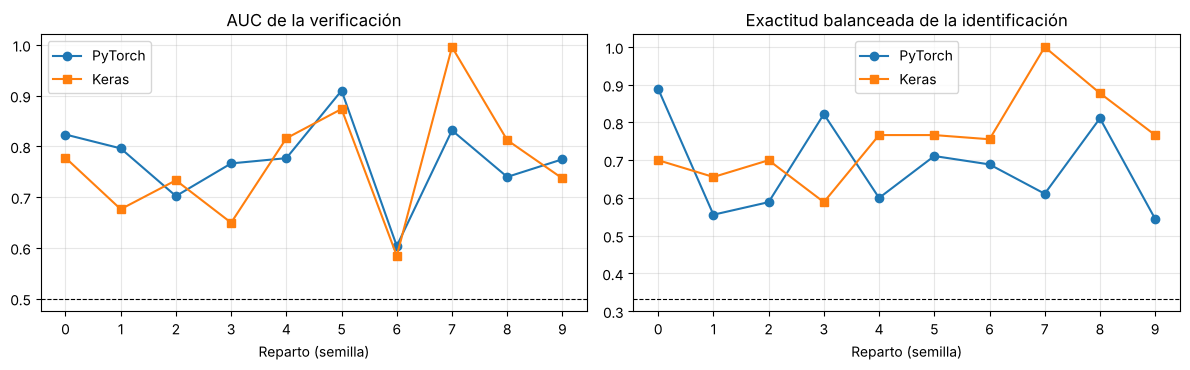

In [7]:
try:
    res_torch = pd.read_csv("resultados/pytorch_repartos.csv")
    res_torch = res_torch[res_torch.modelo == "Siamesa"].reset_index(drop=True)
except FileNotFoundError:
    res_torch = None
    print("No se encontró resultados/pytorch_repartos.csv: ejecute primero el notebook 2.")

if res_torch is not None:
    cols = ["auc", "eer", "verif_acc_bal", "ident_acc_bal"] + [f"{k}-shot" for k in KS]
    comp = pd.DataFrame({
        "PyTorch (media ± desv.)": [f"{res_torch[c].mean():.3f} ± {res_torch[c].std():.3f}" for c in cols],
        "Keras (media ± desv.)": [f"{res_keras[c].mean():.3f} ± {res_keras[c].std():.3f}" for c in cols],
        "Diferencia de medias (Keras − PyTorch)": [f"{res_keras[c].mean() - res_torch[c].mean():+.3f}" for c in cols],
    }, index=["AUC verificación", "EER verificación", "Exactitud verificación (bal.)", "Exactitud identificación (bal.)", "1-shot", "2-shot", "3-shot", "5-shot"])
    print(comp.to_string())
    print()
    # Prueba pareada: el mismo reparto en ambos frameworks
    from scipy import stats
    for c in ["auc", "ident_acc_bal"]:
        t, p = stats.ttest_rel(res_keras[c], res_torch[c])
        print(f"Prueba t pareada en '{c}' (10 repartos): diferencia media {np.mean(res_keras[c] - res_torch[c]):+.3f}, p = {p:.3f}")
    print(f"Correlación entre frameworks del AUC por reparto: {np.corrcoef(res_keras['auc'], res_torch['auc'])[0, 1]:.2f}")

    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
    for eje, col, titulo in zip(ejes, ["auc", "ident_acc_bal"], ["AUC de la verificación", "Exactitud balanceada de la identificación"]):
        eje.plot(SEMILLAS, res_torch[col], "o-", label="PyTorch"); eje.plot(SEMILLAS, res_keras[col], "s-", label="Keras")
        eje.set(xlabel="Reparto (semilla)", title=titulo); eje.set_xticks(SEMILLAS); eje.legend()
    ejes[0].axhline(0.5, color="k", ls="--", lw=0.8); ejes[1].axhline(1 / 3, color="k", ls="--", lw=0.8)
    plt.tight_layout(); plt.show()

**Lectura de la comparación.**

- **Verificación: no hay diferencia apreciable.** El AUC promedio es 0.772 en PyTorch y 0.765 en Keras (diferencia de −0.007; prueba t pareada p = 0.807), y el EER y la exactitud
  de verificación también son parecidos.
- **Identificación: Keras queda mejor en promedio** (0.758 frente a 0.682, una diferencia de +0.076; p = 0.220) y lo mismo con 1, 2, 3 y 5 fotos de referencia (entre +0.055 y +0.066). Con
  10 repartos y p > 0.05, **no se puede afirmar que la diferencia sea real**: puede ser variación de los repartos y de las inicializaciones.
- **No se deben atribuir las diferencias al framework.** Aunque la arquitectura, la pérdida y los repartos son los mismos, los detalles de implementación no son idénticos: la
  inicialización de pesos (Glorot en Keras, Kaiming en PyTorch), el momento de la normalización por lotes, y las capas de aumento de datos de cada librería. La correlación entre frameworks del AUC por reparto es de 0.68:
  los repartos difíciles lo son en ambos, pero no de manera idéntica.
- **Tiempo.** En CPU, Keras entrena en unos 18 s por reparto y PyTorch en unos 24 s (incluyendo la evaluación de las referencias). Con tan pocos datos la diferencia es irrelevante.

### Cuándo conviene cada uno

| | PyTorch | TensorFlow + Keras |
|---|---|---|
| Bucle de entrenamiento | Se escribe de forma natural y explícita, paso a paso. | Se escribe con `tf.GradientTape` (como aquí) o se usa `fit`, que es más corto para pérdidas estándar. |
| Triplet Loss | Se programa con operaciones de tensores; hay `nn.TripletMarginLoss` para tripletas ya formadas. | Se programa con operaciones de TensorFlow; no hay una pérdida de tripletas lista para el muestreo del lote usado aquí. |
| Modelo de tres ramas | Se llama a la misma red tres veces en el código. | Se arma de forma explícita con la API funcional, y queda dibujado en el `summary`. |
| Depuración | Ejecución inmediata, fácil de inspeccionar. | Necesita cuidado con `tf.function` (por ejemplo, crear las variables del optimizador antes de compilar el paso). |

# Conclusiones de la Parte 3

1. La misma red siamesa con Triplet Loss *batch-all* se pudo implementar en Keras con resultados comparables a PyTorch en verificación (AUC 0.765 frente a 0.772).
2. En identificación, Keras quedó por encima en este experimento (0.758 frente a 0.682), pero la diferencia no es estadísticamente concluyente (p = 0.220) y no se debe atribuir al framework.
3. El patrón de resultados es el mismo en ambos: la red aprende, la variabilidad entre repartos es alta con 38 fotos, y registrar a una persona con una sola foto funciona casi tan bien como con cinco.
4. Para mejorar de forma real el sistema hacen falta más fotos y más personas, o partir de un modelo preentrenado en reconocimiento facial, y no cambiar de framework.

---
## Referencias

- Hermans, A., Beyer, L., y Leibe, B. (2017). *In defense of the triplet loss for person re-identification*. arXiv:1703.07737.
- Koch, G., Zemel, R., y Salakhutdinov, R. (2015). Siamese neural networks for one-shot image recognition. *ICML Deep Learning Workshop*.
- Schroff, F., Kalenichenko, D., y Philbin, J. (2015). FaceNet: A unified embedding for face recognition and clustering. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 815–823.
- Zhang, K., Zhang, Z., Li, Z., y Qiao, Y. (2016). Joint face detection and alignment using multitask cascaded convolutional networks. *IEEE Signal Processing Letters, 23*(10), 1499–1503.
- Documentación de PyTorch (pytorch.org), TensorFlow / Keras (keras.io) y scikit-learn (scikit-learn.org).